# Problem Set 1 

**Machine Learning for Public Policy**

Jay Ballesteros

October 15, 2026

## Q1 
**(a) Provide a sketch of typical (squared) bias, variance, training error, test error, and Bayes (or irreducible) error curves, on a single plot, as we go from less flexible statistical learning methods towards more flexible approaches. The x-axis should represent the amount of flexibility in the method, and the y-axis should represent the values for each curve. There should be five curves. Make sure to label each one.2**

<div>
<img src="a_sketch.png" width="400"/>
</div>


**(b) Explain why each of the five curves has the shape displayed in Question (1a).**

In all of the five curves, the curves movement signal how much will $\hat{f}$ changes if the of the model increases.

For each of the lines:
1. Test MSE (black line): The test MSE starts high, at approximately 38, when flexibility is low. It decreases quickly to approximately 3 at a flexibility of 12–15. It stays almost constant until approximately 23. Then it increases to approximately 6 at a flexibility of 25. This gives a U shape: the test MSE is the sum of the squared bias, the variance, and the irreducible error, so it decreases while bias decreases and increases when variance starts to increase.
2. Squared bias (blue line): The squared bias starts at approximately 36 when flexibility is low. It decreases quickly as flexibility increases, and it reaches approximately 0 at a flexibility of 15. It stays near 0 after that point. A more flexible method can fit the true shape of f more closely, so the bias decreases.
3. Variance (gray line): The variance starts low, at approximately 1. It stays low for most of the range. After a flexibility of approximately 20, it increases, and it reaches approximately 5 at a flexibility of 25. A more flexible method changes more when the training data changes, so the variance increases.
4. Irreducible error, Var(ε) (dashed line): The irreducible error is a horizontal line at approximately 3. It does not change with flexibility, because no method can reduce the noise in the data. It is the lower limit for the test MSE.

## Q2
**What are the advantages and disadvantages of a very flexible (versus a less flexible) approach for regression or classification? Under what circumstances might a more flexible approach be preferred to a less flexible approach? When might a less flexible approach be preferred?**

When it comes to very flexible errors approaches (non-parametric) you can loose explainabilty of the model. Also, way more variance in the reducible error (MSE) and risk of overfitting. The main advantage though is, whitin that same flexibility, the models might fit a wider range of possible paterns of $f(X)$. 

In the specific case of the less flexible approach (parametric), models are easier to explain and interpret. Also the can be more accurate with prediction when its time to implement them with test data (as long as a near-linear true $f$, a small $n$, or much noise.). The main trade-off is that they are more biased. 

We might preferred a more flexible approach when our objective is to get more accurate predictions, and not necessarily have explainability of the predictions itself. And we might want a less flexible one when we are more interested in inference. 

## Q3

**(a) To begin, load in the Boston data set, which is available on Canvas and/or can be loaded as part of the ISLP library (in Python).**

In [2]:
from ISLP import load_data
Boston = load_data('Boston')

In [3]:
Boston

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0


**(b) How many rows are in this data set? How many columns? What do the rows and columns represent?**

There are 506 rows and 13 columns. According to the [documentation](https://islp.readthedocs.io/en/latest/datasets/Boston.html), each row represents a census tracts (housing values in 506 suburbs of Boston). And the columns, all in numeric values, are:

| Variable  | Description                                                           |
|-----------|-----------------------------------------------------------------------|
| `crim`    | Per capita crime rate by town                                         |
| `zn`      | Proportion of residential land zoned for lots over 25,000 sq.ft.      |
| `indus`   | Proportion of non-retail business acres per town                      |
| `chas`    | Charles River dummy variable (= 1 if tract bounds river; 0 otherwise) |
| `nox`     | Nitrogen oxides concentration (parts per 10 million)                  |
| `rm`      | Average number of rooms per dwelling                                  |
| `age`     | Proportion of owner-occupied units built prior to 1940                |
| `dis`     | Weighted mean of distances to five Boston employment centres          |
| `rad`     | Index of accessibility to radial highways                             |
| `tax`     | Full-value property-tax rate per $10,000                              |
| `ptratio` | Pupil-teacher ratio by town                                           |
| `lstat`   | Lower status of the population (percent)                              |
| `medv`    | Median value of owner-occupied homes in $1000s                        |



In [7]:
Boston.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  lstat    506 non-null    float64
 12  medv     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


**(c) Make some pairwise scatterplots of the predictors (columns) in this data set (and display a minimum of five of those plots). Describe your findings.**

Considering the per-capita crime rate by town (`crim`) as y-axis, I noticed a few patterns:

1. The higher the proportion of owner-occupied units built prior to 1940, the higher the crime. 
2. Places where full-value property-tax rate was above 600 (per $10,000 values), concentrated higher crime rates. 
3. The lower the median value of owner-occupied homes is, higher the crime rate as well. 
4. There's a notorius positive correlation with the average number of rooms per dwelling (`rm`)and crime rates. 
5. Same with the indicator `lstat` (lower status of the population (percent)): apparent high positive correlation.

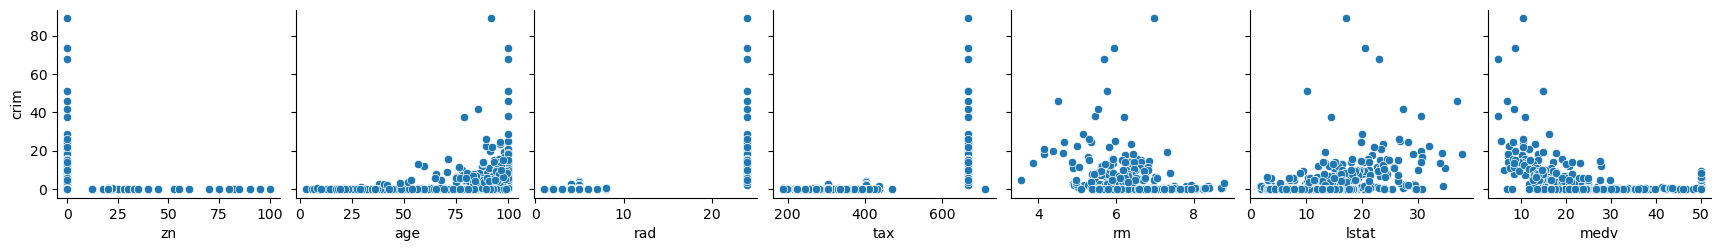

In [13]:
import seaborn as sns
sns.pairplot(
    Boston,
    x_vars=["zn", "age", "rad", "tax", "rm", "lstat", "medv"],
    y_vars=["crim"],
)

**(d) Are any of the predictors associated with per capita crime rate? If so, explain the relationship (for the predictors whose plots you displayed in the previous question).**

Yes, mostly in `rm` and `lstat`. Rationalle is the previous answer.

**(e) Do any of the Boston census tracts appear to have particularly high crime rates? Tax rates? Pupil-teacher ratios? Comment on the range of each of the three listed predictors**

- Crime rates: Yes. Even though that the mean is 3.6 (and median at 0.256!) there are some crazy outliers with rates above 50. Nonetheless standard deviation is at 8.6.
- Tax rates: With taxes, the standard deviation is the highest of the three predictors. Therefore a lot of censustract with particularly high tax rates (more separated from the mean).
- Pupil-teacher ratio: Lowest standard deviation of the listed predictos. Therefore, the distribution is a bit more equal.

In [25]:
Boston[['crim', 'tax','ptratio']].describe()

,crim,tax,ptratio
count,506.000000,506.000000,506.000000
mean,3.613524,408.237154,18.455534
std,8.601545,168.537116,2.164946
min,0.006320,187.000000,12.600000
25%,0.082045,279.000000,17.400000
50%,0.256510,330.000000,19.050000
75%,3.677083,666.000000,20.200000
max,88.976200,711.000000,22.000000


<Axes: xlabel='crim'>

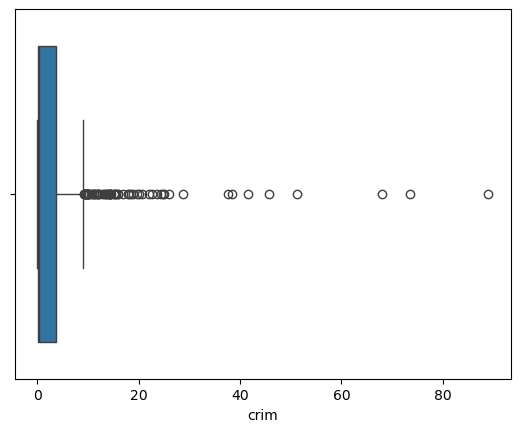

In [30]:
sns.boxplot(x=Boston['crim'])

<Axes: xlabel='crim', ylabel='Count'>

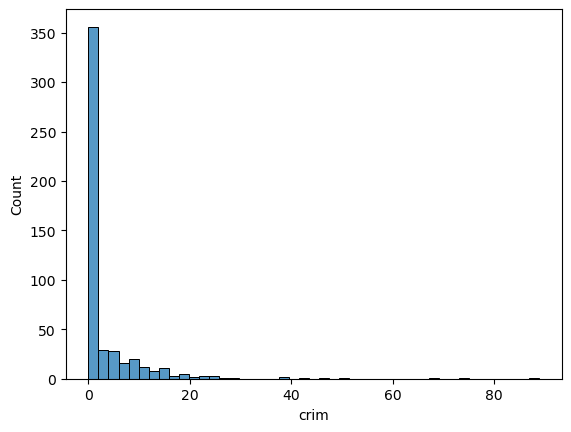

In [ ]:
sns.histplot(x=Boston['crim'])

<Axes: xlabel='tax'>

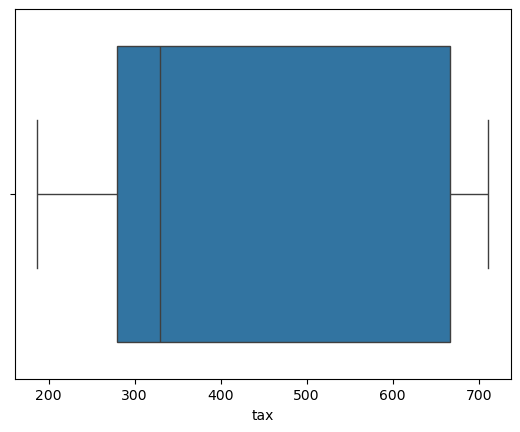

In [29]:
sns.boxplot(x=Boston['tax'])

<Axes: xlabel='tax', ylabel='Count'>

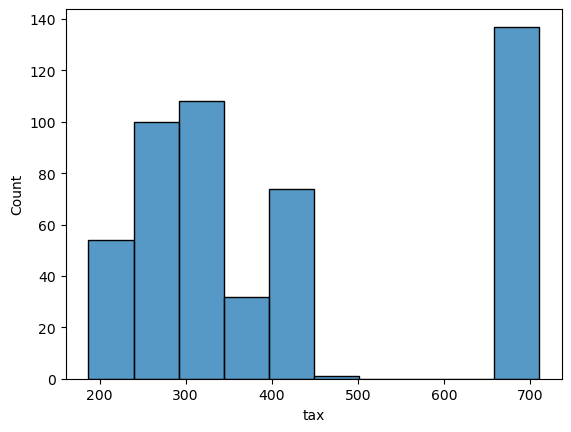

In [39]:
sns.histplot(x=Boston['tax'])

<Axes: xlabel='ptratio'>

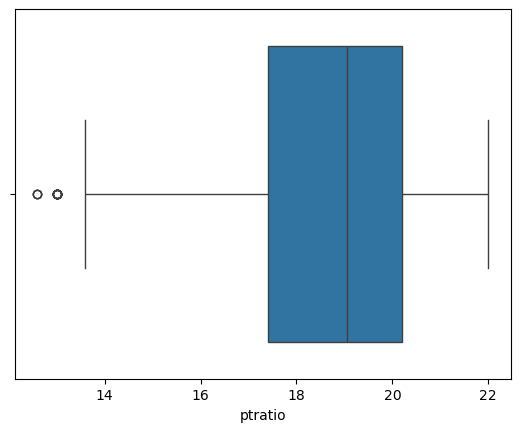

In [31]:
sns.boxplot(x=Boston['ptratio'])

<Axes: xlabel='ptratio', ylabel='Count'>

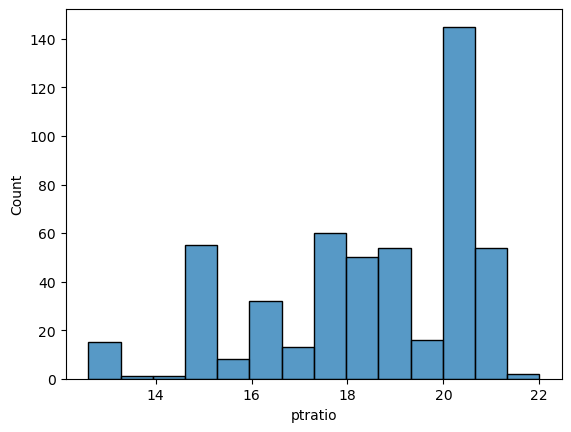

In [40]:
sns.histplot(x=Boston['ptratio'])

**(f) How many of the census tracts in this data set bound the Charles River?**
- Only 35 out of 506! That's about ~7%.

In [45]:
Boston['chas'].value_counts()

chas
0    471
1     35
Name: count, dtype: int64

**(g) What is the median pupil-teacher ratio among the census tracts in this data set?**
- 19.05

In [48]:
Boston['ptratio'].describe()

count    506.000000
mean      18.455534
std        2.164946
min       12.600000
25%       17.400000
50%       19.050000
75%       20.200000
max       22.000000
Name: ptratio, dtype: float64

**(h) Which Boston census tract has lowest median value of owner-occupied homes? What are the values of the other predictors for that census tract, and how do those values compare to the overall ranges for those predictors. Comment on your findings.**

- We have two tied! The 398 and 405 census tracts.
- They both have significant higher crime rates compared to the median. Same case with tax rates and most indicators.

In [51]:
Boston['medv'].sort_values(ascending=True)

398     5.0
405     5.0
400     5.6
399     6.3
414     7.0
       ... 
166    50.0
195    50.0
283    50.0
225    50.0
186    50.0
Name: medv, Length: 506, dtype: float64

In [75]:
lowest1 = Boston.loc[398]
lowest2 = Boston.loc[405]

print(lowest1)
print(lowest2)


crim        38.3518
zn           0.0000
indus       18.1000
chas         0.0000
nox          0.6930
rm           5.4530
age        100.0000
dis          1.4896
rad         24.0000
tax        666.0000
ptratio     20.2000
lstat       30.5900
medv         5.0000
Name: 398, dtype: float64
crim        67.9208
zn           0.0000
indus       18.1000
chas         0.0000
nox          0.6930
rm           5.6830
age        100.0000
dis          1.4254
rad         24.0000
tax        666.0000
ptratio     20.2000
lstat       22.9800
medv         5.0000
Name: 405, dtype: float64


In [72]:
Boston.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


**(i) In this data set, how many of the census tract average more than seven rooms per dwelling? More than eight rooms per dwellin? Comment on the census tracts that average more than eight rooms per dwelling**

- 64 census tract with > 7 rooms per dwelling. 13 with > 8. 
- Comparing with other variables, the census tracts with >8 rooms per dwelling, have lower crime rates and lstat. Higher medv tho.

In [82]:
(Boston['rm'] > 7).sum()

np.int64(64)

In [ ]:
(Boston['rm'] > 8).sum()

np.int64(13)

In [ ]:
Boston[['medv', 'lstat', 'crim']].mean()

medv     22.532806
lstat    12.653063
crim      3.613524
dtype: float64

In [83]:
Boston.loc[Boston['rm'] > 8, ['medv', 'lstat', 'crim']].mean()

medv     44.200000
lstat     4.310000
crim      0.718795
dtype: float64

## Q4

Suppose we have a data set with five predictors:

- $X_1 =$ GPA from high school
- $X_2 =$ IQ
- $X_3 =$ Level ($1$ for College and $0$ for High School)
- $X_4 =$ Interaction between GPA and IQ
- $X_5 =$ Interaction between GPA and Level

The response is starting salary after graduation (in thousands of dollars).

Suppose we use least squares to fit the model, and get:

$$
\hat{\beta}_0 = 50,\quad
\hat{\beta}_1 = 20,\quad
\hat{\beta}_2 = 0.07,\quad
\hat{\beta}_3 = 35,\quad
\hat{\beta}_4 = 0.01,\quad
\hat{\beta}_5 = -10.
$$

The fitted model is:

$$
\begin{aligned}
\hat{Y} ={}& \hat{\beta}_0
+ \hat{\beta}_1 \text{GPA}
+ \hat{\beta}_2 \text{IQ}
+ \hat{\beta}_3 \text{Level}
+ \hat{\beta}_4 (\text{GPA} \times \text{IQ})
+ \hat{\beta}_5 (\text{GPA} \times \text{Level}).
\end{aligned}
$$

**(a) Which answer is correct, and why?**

iii. For a fixed value of IQ and GPA, high school graduates earn more, on average, than college graduates provided that the GPA is high enough.

Because the college value is 35 but the GPA and Level interaction discounts 10 for each GPA point. 

**(b) Predict the salary of a college graduate with IQ of 110 and a GPA of 4.0.**

$$\hat{Y} = 50 + 20(4.0) + 0.07(110) + 35(1) + 0.01 (4.0 x 110) -10(4.0 x 1)$$

$$= 50 + 80 + 7.7 + 35 + 4.4 − 40$$

$$= 137.1  \text{(in thousands of dolars)}$$

**(c) True or false: Since the coefficient for the GPA/IQ interaction term is very small, there is very little evidence of an interaction effect. Justify your answer**

False, because the size of a coefficient does not show the strength of the evidence.


## Q5

**This problem involves the Boston data set (which is used as an example in the lab at the end of Chapter 3 in the textbook). We will now try to predict per capita crime rate using the other variables in this data set. In other words, per capita crime rate is the response (outcome), and the other variables are the predictors.**

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

In [84]:
df = Boston.copy()

y = "crim"
predictors = [c for c in df.columns if c != y]
predictors

['zn',
 'indus',
 'chas',
 'nox',
 'rm',
 'age',
 'dis',
 'rad',
 'tax',
 'ptratio',
 'lstat',
 'medv']



**(a) For each predictor, fit a simple linear regression model to predict the response. Describe your results. In which of the models is there a statistically significant association between the predictor and the response? Create some plots (and display a minimum of five of those plots) to back up your assertions.**

In [87]:
slr_models = {}
rows = []
for x in predictors:
    m = smf.ols(f"{y} ~ {x}", data=df).fit()
    slr_models[x] = m
    rows.append({
        "predictor": x,
        "coef": m.params[x],
        "std_err": m.bse[x],
        "t": m.tvalues[x],
        "p_value": m.pvalues[x],
        "R2": m.rsquared,
    })

slr = pd.DataFrame(rows).set_index("predictor").sort_values("p_value")
slr["significant_5pct"] = slr["p_value"] < 0.05
slr.round(4)

,coef,std_err,t,p_value,R2,significant_5pct
predictor,,,,,,
rad,0.6179,0.0343,17.9982,0.0000,0.3913,True
tax,0.0297,0.0018,16.0994,0.0000,0.3396,True
lstat,0.5488,0.0478,11.4907,0.0000,0.2076,True
nox,31.2485,2.9992,10.4190,0.0000,0.1772,True
indus,0.5098,0.0510,9.9908,0.0000,0.1653,True
medv,-0.3632,0.0384,-9.4597,0.0000,0.1508,True
dis,-1.5509,0.1683,-9.2135,0.0000,0.1441,True
age,0.1078,0.0127,8.4628,0.0000,0.1244,True
ptratio,1.1520,0.1694,6.8014,0.0000,0.0841,True


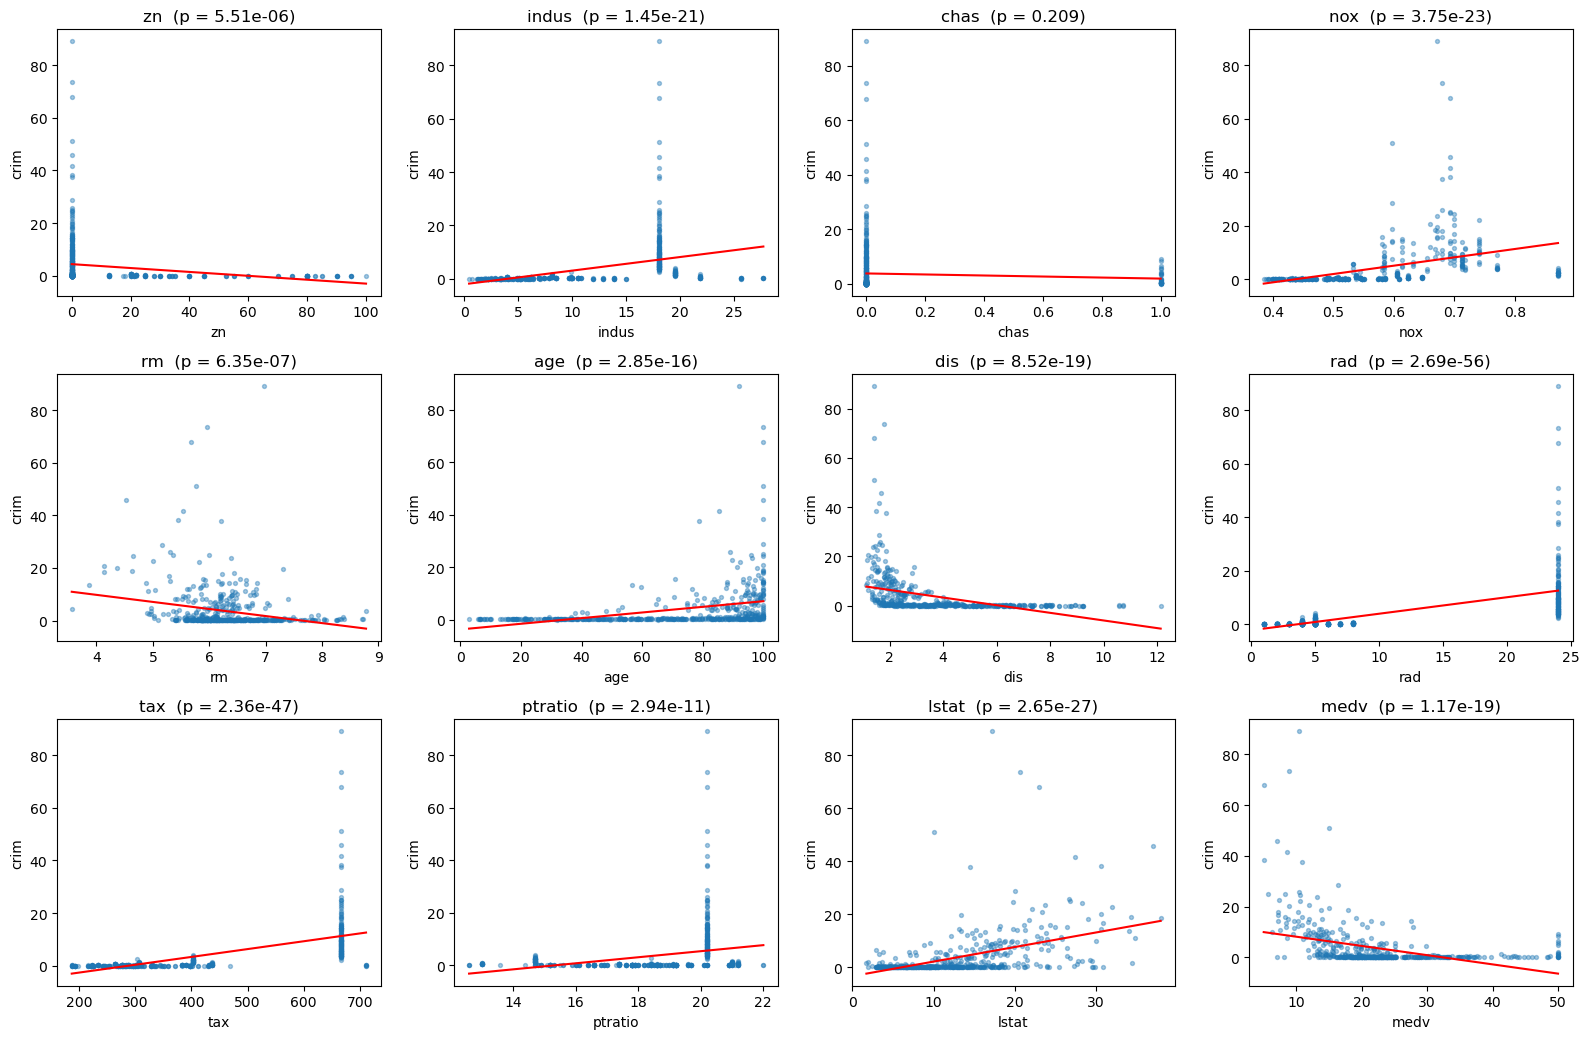

In [88]:
ncols = 4
nrows = int(np.ceil(len(predictors) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.5 * nrows))

for ax, x in zip(axes.flat, predictors):
    m = slr_models[x]
    ax.scatter(df[x], df[y], s=8, alpha=0.4)
    xs = np.linspace(df[x].min(), df[x].max(), 100)
    ax.plot(xs, m.params["Intercept"] + m.params[x] * xs, color="red")
    ax.set_title(f"{x}  (p = {m.pvalues[x]:.3g})")
    ax.set_xlabel(x)
    ax.set_ylabel(y)

for ax in axes.flat[len(predictors):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()



**(b) Fit a multiple regression model to predict the response using all of the predictors. Describe your results. For which predictors can we reject the null hypothesis**

$$
H_0: \beta_j = 0?
$$



In [90]:
mlr = smf.ols(f"{y} ~ " + " + ".join(predictors), data=df).fit()

mlr_tab = pd.DataFrame({
    "coef": mlr.params,
    "std_err": mlr.bse,
    "t": mlr.tvalues,
    "p_value": mlr.pvalues,
}).drop("Intercept")
mlr_tab["reject_H0_5pct"] = mlr_tab["p_value"] < 0.05

print(f"R2 = {mlr.rsquared:.3f}, adj R2 = {mlr.rsquared_adj:.3f}, F p-value = {mlr.f_pvalue:.3g}")
mlr_tab.round(4)

R2 = 0.449, adj R2 = 0.436, F p-value = 2.03e-56


,coef,std_err,t,p_value,reject_H0_5pct
zn,0.0457,0.0188,2.4326,0.0153,True
indus,-0.0584,0.0836,-0.6977,0.4857,False
chas,-0.8254,1.1834,-0.6975,0.4858,False
nox,-9.9576,5.2898,-1.8824,0.0604,False
rm,0.6289,0.6071,1.0359,0.3007,False
age,-0.0008,0.0179,-0.0473,0.9623,False
dis,-1.0122,0.2825,-3.5836,0.0004,True
rad,0.6125,0.0875,6.9967,0.0000,True
tax,-0.0038,0.0052,-0.7300,0.4658,False
ptratio,-0.3041,0.1864,-1.6316,0.1034,False


**(c) How do your results from Question (5a) compare to your results from Question (5b)? Create a plot displaying the univariate regression coefficients from Question (5a) on the x-axis, and the multiple regression coefficients from Question (5b) on the y-axis. That is, each predictor is displayed as a single point in the plot. Its coefficient in a simple linear regression model is shown on the x-axis, and its coefficient estimate in the multiple linear regression model is shown on the y-axis.**

,simple_coef,multiple_coef,simple_sig,multiple_sig
zn,-0.0739,0.0457,True,True
indus,0.5098,-0.0584,True,False
chas,-1.8928,-0.8254,False,False
nox,31.2485,-9.9576,True,False
rm,-2.6841,0.6289,True,False
age,0.1078,-0.0008,True,False
dis,-1.5509,-1.0122,True,True
rad,0.6179,0.6125,True,True
tax,0.0297,-0.0038,True,False
ptratio,1.1520,-0.3041,True,False


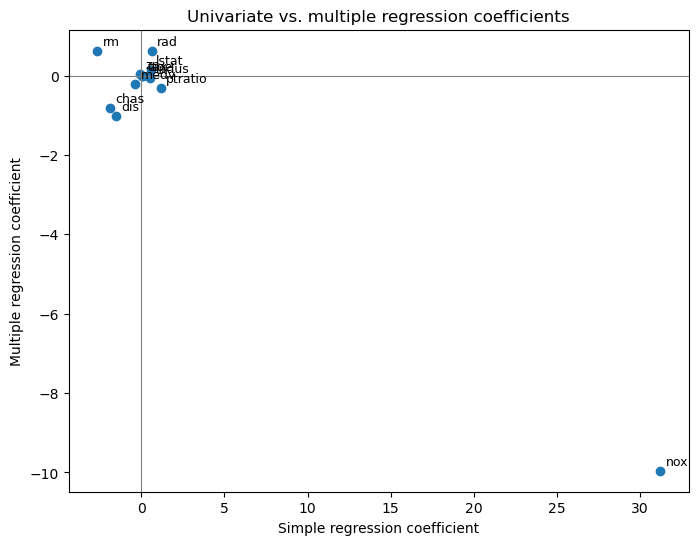

In [91]:
comp = pd.DataFrame({
    "simple_coef": slr["coef"],
    "multiple_coef": mlr_tab["coef"],
    "simple_sig": slr["significant_5pct"],
    "multiple_sig": mlr_tab["reject_H0_5pct"],
}).loc[predictors]
display(comp.round(4))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(comp["simple_coef"], comp["multiple_coef"])
for x, r in comp.iterrows():
    ax.annotate(x, (r["simple_coef"], r["multiple_coef"]),
                textcoords="offset points", xytext=(4, 4), fontsize=9)
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Simple regression coefficient")
ax.set_ylabel("Multiple regression coefficient")
ax.set_title("Univariate vs. multiple regression coefficients")
plt.show()

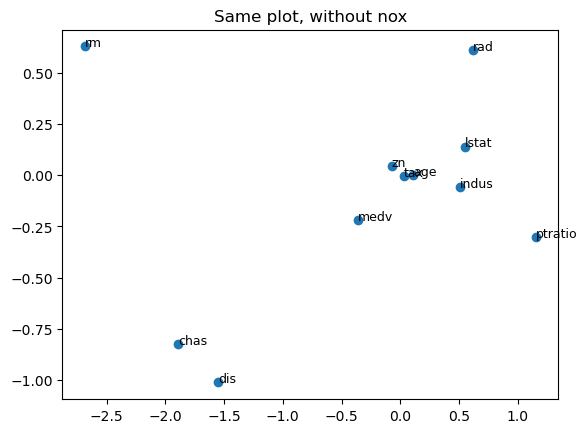

In [92]:
c2 = comp.drop(index="nox")
plt.scatter(c2["simple_coef"], c2["multiple_coef"])
for x, r in c2.iterrows():
    plt.annotate(x, (r["simple_coef"], r["multiple_coef"]), fontsize=9)
plt.title("Same plot, without nox"); plt.show()

**(d) Is there evidence of non-linear association between any of the predictors and the response? To answer this question, for each predictor \(X\) (that isn't an indicator variable), fit a model of the form**

$$
Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \varepsilon.
$$


In [93]:
binary = [x for x in predictors if df[x].nunique() == 2]   # this removes chas
cont = [x for x in predictors if x not in binary]

rows = []
for x in cont:
    lin = smf.ols(f"{y} ~ {x}", data=df).fit()
    cub = smf.ols(f"{y} ~ {x} + I({x}**2) + I({x}**3)", data=df).fit()
    f_test = anova_lm(lin, cub)  # linear vs. cubic
    rows.append({
        "predictor": x,
        "p_X": cub.pvalues[x],
        "p_X2": cub.pvalues[f"I({x} ** 2)"],
        "p_X3": cub.pvalues[f"I({x} ** 3)"],
        "R2_linear": lin.rsquared,
        "R2_cubic": cub.rsquared,
        "F_test_p": f_test["Pr(>F)"].iloc[1],
    })

poly = pd.DataFrame(rows).set_index("predictor")
poly["nonlinear_evidence"] = (poly[["p_X2", "p_X3"]] < 0.05).any(axis=1)
print("Skipped (binary):", binary)
poly.round(4)

Skipped (binary): ['chas']


,p_X,p_X2,p_X3,R2_linear,R2_cubic,F_test_p,nonlinear_evidence
predictor,,,,,,,
zn,0.0026,0.0938,0.2295,0.0402,0.0582,0.0085,False
indus,0.0001,0.0000,0.0000,0.1653,0.2597,0.0000,True
nox,0.0000,0.0000,0.0000,0.1772,0.2970,0.0000,True
rm,0.2118,0.3641,0.5086,0.0481,0.0678,0.0052,False
age,0.1427,0.0474,0.0067,0.1244,0.1742,0.0000,True
dis,0.0000,0.0000,0.0000,0.1441,0.2778,0.0000,True
rad,0.6234,0.6130,0.4823,0.3913,0.4000,0.0261,False
tax,0.1097,0.1375,0.2439,0.3396,0.3689,0.0000,False
ptratio,0.0030,0.0041,0.0063,0.0841,0.1138,0.0003,True
